### Mapping NYC Facilities: Comparing Health and Human Services Facilities in Brooklyn and the Bronx

Main research question:
How does the number and percentage of health and human services facilities differ between Brooklyn and the Bronx??
Supporting questions:
1. Which borough has the most recorded facilities?
2. Which facility categories (facdomain) are most common citywide?
3. How do health, education, cultural, and parks facilities differ across boroughs?
4. What percentage of each borough’s facilities belongs to each category?
5. Which categories have the most missing address or location information?

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/Users/carolinekinya/Downloads/Facilities_Database_20261008.csv")

# Exploratory Data Analysis

In [3]:
df

,uid,facname,addressnum,streetname,address,city,boro,borocode,zipcode,latitude,...,opabbrev,overlevel,overagency,overabbrev,datasource,facdomain,schooldist,policeprct,servarea,geometry
0,00041e822a3da19f11cb931f6b25b13f,560 W 43RD STREET PARKING CORP,NaN,NaN,555 WEST 42 STREET,NEW YORK,MANHATTAN,1,10036.0,40.760963,...,Non-public,City,NYC Department of Consumer Affairs,NYCDCA,dca_operatingbusinesses,CORE INFRASTRUCTURE AND TRANSPORTATION,2.0,10,Local,POINT(984912.9262504578 216516.07293081284)
1,0004a8532521d7d9879f82f67f7fb2e5,SIXTEEN SYCAMORES PLAYGROUND,358,SCHERMERHORN STREET,358 SCHERMERHORN STREET,BROOKLYN,BROOKLYN,3,11217.0,40.686533,...,NYCDPR,City,NYC Department of Parks and Recreation,NYCDPR,dpr_parksproperties,"PARKS, GARDENS, AND HISTORICAL SITES",15.0,84,Local,POINT(989713.4305129051 189399.48395442963)
2,00056520e4c5483e13933cda8c8a736d,MARKS JCH OF BENSONHURST DAY CAMP,7802,BAY PARKWAY,7802 BAY PARKWAY,BROOKLYN,BROOKLYN,3,11214.0,40.606376,...,Non-public,City,NYC Department of Health and Mental Hygiene,NYCDOHMH,dohmh_daycare,"EDUCATION, CHILD WELFARE, AND YOUTH",20.0,62,Local,POINT(987095.5382494926 160195.8266620636)
3,0005a5ab702b05d9c4337e743af7d26d,POWELL PLAYGROUND,NaN,NaN,289 PITKIN AVENUE,BROOKLYN,BROOKLYN,3,11212.0,40.671267,...,NYCDPR,City,NYC Department of Parks and Recreation,NYCDPR,dpr_parksproperties,"PARKS, GARDENS, AND HISTORICAL SITES",23.0,73,Local,POINT(1010646.6638479233 183851.5379447937)
4,0005cf2135820de8d20395875ca0e506,CENTER FOR JEWISH HISTORY,15,WEST 16 STREET,15 WEST 16 STREET,NEW YORK,MANHATTAN,1,10011.0,40.738071,...,Non-public,City,NYC Department of Cultural Affairs,NYCDCLA,dcla_culturalinstitutions,LIBRARIES AND CULTURAL PROGRAMS,2.0,13,Regional,POINT(985967.0029587746 208175.9767355919)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34441,R010001,NY WHEEL,155,RICHMOND TERRACE,155 RICHMOND TERRACE,STATEN ISLAND,STATEN ISLAND,5,10301.0,40.647025,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",31.0,120,Local,POINT(962365.8650364876 175014.9505739212)
34442,R020001,LANDMARK COLONY,475,BRIELLE AVENUE,475 BRIELLE AVENUE,STATEN ISLAND,STATEN ISLAND,5,10314.0,40.593719,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",31.0,121,Local,POINT(946532.95936203 155613.43146800995)
34443,X010001,LA CENTRAL,671,BROOK AVENUE,671 BROOK AVENUE,BRONX,BRONX,2,10455.0,40.817688,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",7.0,40,Local,POINT(1008124.4350848198 237194.71119356155)
34444,X020001,SPOFFORD CAMPUS,1201,SPOFFORD AVENUE,1201 SPOFFORD AVENUE,BRONX,BRONX,2,10474.0,40.814349,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",8.0,41,Local,POINT(1014697.9166698456 235985.7119860649)


In [4]:
df.tail()

,uid,facname,addressnum,streetname,address,city,boro,borocode,zipcode,latitude,...,opabbrev,overlevel,overagency,overabbrev,datasource,facdomain,schooldist,policeprct,servarea,geometry
34441,R010001,NY WHEEL,155,RICHMOND TERRACE,155 RICHMOND TERRACE,STATEN ISLAND,STATEN ISLAND,5,10301.0,40.647025,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",31.0,120,Local,POINT(962365.8650364876 175014.9505739212)
34442,R020001,LANDMARK COLONY,475,BRIELLE AVENUE,475 BRIELLE AVENUE,STATEN ISLAND,STATEN ISLAND,5,10314.0,40.593719,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",31.0,121,Local,POINT(946532.95936203 155613.43146800995)
34443,X010001,LA CENTRAL,671,BROOK AVENUE,671 BROOK AVENUE,BRONX,BRONX,2,10455.0,40.817688,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",7.0,40,Local,POINT(1008124.4350848198 237194.71119356155)
34444,X020001,SPOFFORD CAMPUS,1201,SPOFFORD AVENUE,1201 SPOFFORD AVENUE,BRONX,BRONX,2,10474.0,40.814349,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",8.0,41,Local,POINT(1014697.9166698456 235985.7119860649)
34445,X030001,"1560 BOONE AVENUE, BRONX, NY 10460",1560,BOONE AVENUE,1560 BOONE AVENUE,BRONX,BRONX,2,10460.0,40.833665,...,Non-public,City,NYC Department of City Planning,NYCDCP,dcp_pops,"PARKS, GARDENS, AND HISTORICAL SITES",12.0,42,Local,POINT(1016325.0139212608 243025.10056591034)


In [5]:
df.head()

,uid,facname,addressnum,streetname,address,city,boro,borocode,zipcode,latitude,...,opabbrev,overlevel,overagency,overabbrev,datasource,facdomain,schooldist,policeprct,servarea,geometry
0,00041e822a3da19f11cb931f6b25b13f,560 W 43RD STREET PARKING CORP,NaN,NaN,555 WEST 42 STREET,NEW YORK,MANHATTAN,1,10036.0,40.760963,...,Non-public,City,NYC Department of Consumer Affairs,NYCDCA,dca_operatingbusinesses,CORE INFRASTRUCTURE AND TRANSPORTATION,2.0,10,Local,POINT(984912.9262504578 216516.07293081284)
1,0004a8532521d7d9879f82f67f7fb2e5,SIXTEEN SYCAMORES PLAYGROUND,358,SCHERMERHORN STREET,358 SCHERMERHORN STREET,BROOKLYN,BROOKLYN,3,11217.0,40.686533,...,NYCDPR,City,NYC Department of Parks and Recreation,NYCDPR,dpr_parksproperties,"PARKS, GARDENS, AND HISTORICAL SITES",15.0,84,Local,POINT(989713.4305129051 189399.48395442963)
2,00056520e4c5483e13933cda8c8a736d,MARKS JCH OF BENSONHURST DAY CAMP,7802,BAY PARKWAY,7802 BAY PARKWAY,BROOKLYN,BROOKLYN,3,11214.0,40.606376,...,Non-public,City,NYC Department of Health and Mental Hygiene,NYCDOHMH,dohmh_daycare,"EDUCATION, CHILD WELFARE, AND YOUTH",20.0,62,Local,POINT(987095.5382494926 160195.8266620636)
3,0005a5ab702b05d9c4337e743af7d26d,POWELL PLAYGROUND,NaN,NaN,289 PITKIN AVENUE,BROOKLYN,BROOKLYN,3,11212.0,40.671267,...,NYCDPR,City,NYC Department of Parks and Recreation,NYCDPR,dpr_parksproperties,"PARKS, GARDENS, AND HISTORICAL SITES",23.0,73,Local,POINT(1010646.6638479233 183851.5379447937)
4,0005cf2135820de8d20395875ca0e506,CENTER FOR JEWISH HISTORY,15,WEST 16 STREET,15 WEST 16 STREET,NEW YORK,MANHATTAN,1,10011.0,40.738071,...,Non-public,City,NYC Department of Cultural Affairs,NYCDCLA,dcla_culturalinstitutions,LIBRARIES AND CULTURAL PROGRAMS,2.0,13,Regional,POINT(985967.0029587746 208175.9767355919)


In [6]:
df.sample(6)

,uid,facname,addressnum,streetname,address,city,boro,borocode,zipcode,latitude,...,opabbrev,overlevel,overagency,overabbrev,datasource,facdomain,schooldist,policeprct,servarea,geometry
7544,36163160d88304ceb4042a8cdfe2362a,THE CHILDRENS AID SOCIETY,3703,10 AVENUE,3703 10 AVENUE,NEW YORK,MANHATTAN,1,10034.0,40.858411,...,NaN,City,NYC Department of Youth and Community Development,NYCDYCD,moeo_socialservicesitelocations,"EDUCATION, CHILD WELFARE, AND YOUTH",6.0,34,Local,POINT(1005740.0712952614 252029.2522854805)
1843,0c4ca9b17f55c92697c192bcda261d01,BRONX LAB SCHOOL,800,EAST GUN HILL ROAD,800 EAST GUN HILL ROAD,BRONX,BRONX,2,10467.0,40.875193,...,NYCDOE,City,NYC Department of Education,NYCDOE,doe_lcgms,"EDUCATION, CHILD WELFARE, AND YOUTH",11.0,47,Local,POINT(1022514.8415770531 258164.41053819656)
3892,1af7f9d8adaef1a41a813254a9c05a63,NORD ANGLIA INTERNATIONAL SCHOOL,44,EAST 2 STREET,44 EAST 2 STREET,NEW YORK,MANHATTAN,1,10003.0,40.724889,...,Non-public,City,NYC Department of Education,NYCDOE,nysed_activeinstitutions,"EDUCATION, CHILD WELFARE, AND YOUTH",1.0,9,Local,POINT(987123.288547039 203373.2168879509)
901,05bd8f8db2c32521606dbf22faaa33e2,CRIM COURTHOUSE/DETENTION CPLX,100,CENTRE STREET,100 CENTRE STREET,NEW YORK,MANHATTAN,1,10013.0,40.716358,...,NYCDA-MN,City,NYC District Attorney - Manhattan,NYCDA-MN,dcp_colp,ADMINISTRATION OF GOVERNMENT,2.0,5,Regional,POINT(984083.117898941 200265.0517168045)
30629,e5f4d0439a2f0aeade0272438dc2f1f8,ST. PETER AND ST. PAUL,838,BROOK AVENUE,838 BROOK AVENUE,BRONX,BRONX,2,10451.0,40.821856,...,Non-public,City,NYC Department of Education,NYCDOE,nysed_activeinstitutions,"EDUCATION, CHILD WELFARE, AND YOUTH",7.0,40,Local,POINT(1009014.2323722839 238713.95700502396)
23181,ac7ccb1e29139645153c7b4ed02f571e,P.S. 009 SARAH ANDERSON,100,WEST 84 STREET,100 WEST 84 STREET,NEW YORK,MANHATTAN,1,10024.0,40.785111,...,NYCDOE,City,NYC Department of Education,NYCDOE,doe_lcgms,"EDUCATION, CHILD WELFARE, AND YOUTH",3.0,20,Local,POINT(991487.5574827194 225314.8994383812)


## Understanding Facilities database

In [7]:
df.groupby('overagency').size().reset_index(name='Count')

,overagency,Count
0,Amtrak,4
1,Brooklyn Bridge Park Corporation,1
2,Brooklyn Public Library,68
3,City University of New York,1
4,County Clerk,3
...,...,...
151,Roosevelt Island Operating Corporation,11
152,"The New York State Office of Parks, Recreation...",1088
153,Trust for Governors Island,7
154,US Courts,12


In [8]:
df.groupby('facdomain').size().reset_index(name='Count').sort_values('Count', ascending=False)

,facdomain,Count
2,"EDUCATION, CHILD WELFARE, AND YOUTH",15420
3,HEALTH AND HUMAN SERVICES,5740
1,CORE INFRASTRUCTURE AND TRANSPORTATION,5489
5,"PARKS, GARDENS, AND HISTORICAL SITES",3677
4,LIBRARIES AND CULTURAL PROGRAMS,2647
0,ADMINISTRATION OF GOVERNMENT,996
6,"PUBLIC SAFETY, EMERGENCY SERVICES, AND ADMINIS...",477


In [9]:
df.groupby('datasource').size().reset_index(name='Count').sort_values('Count', ascending=False).head(15)

,datasource,Count
32,moeo_socialservicesitelocations,4179
43,nysed_activeinstitutions,4092
1,dca_operatingbusinesses,2725
11,dohmh_daycare,2525
24,dycd_service_sites,2440
2,dcla_culturalinstitutions,2306
17,dpr_parksproperties,2052
10,doe_universalprek,1970
9,doe_lcgms,1871
3,dcp_colp,1784


In [10]:
df.groupby('overabbrev').size().reset_index(name='Count').sort_values('Count', ascending=False)

,overabbrev,Count
101,NYCDOE,8069
113,NYCDYCD,5383
103,NYCDOHMH,3164
91,NYCDCA,2730
93,NYCDCLA,2311
...,...,...
54,NYCCB310,1
90,NYCDA-SNP,1
55,NYCCB311,1
56,NYCCB312,1


In [11]:
df.groupby('servarea').size().reset_index(name='Count').sort_values('Count', ascending=False)

,servarea,Count
0,Local,25096
1,Regional,9350


In [12]:
df.groupby('council').size().reset_index(name='Count').sort_values('Count', ascending=False).head(10)

,council,Count
1,1,1698
3,3,1472
8,8,1268
33,33,1170
4,4,1160
17,17,1042
2,2,991
9,9,968
49,49,930
0,0,821


In [13]:
df.groupby('servarea').size().reset_index(name='Count').sort_values('Count', ascending=False)#

,servarea,Count
0,Local,25096
1,Regional,9350


In [14]:
df.groupby('facname').size().reset_index(name='count').sort_values('count', ascending=False).head(15)

,facname,count
21467,SP PLUS CORPORATION,159
18049,PARK,121
16717,OFFICES,108
25728,YMCA OF GREATER NEW YORK,85
15687,NEW YORK EDGE INC,81
4178,BRONXWORKS INC,60
18573,POLICE ATHLETIC LEAGUE INC,59
5133,CATHOLIC CHARITIES NEIGHBORHOOD SERVICES INC,56
9792,GOOD SHEPHERD SERVICES,56
23247,THE JEWISH ASSOCIATION FOR SERVICES FOR THE AGED,53


# Cleaning the data 

## Missing Data

In [16]:
missing_data = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_data = missing_data.sort_values(
    "Missing Values",
    ascending=False
)

missing_data

,Missing Values,Missing Percentage
captype,32299,93.77
optype,9338,27.11
opabbrev,9318,27.05
addressnum,8546,24.81
streetname,8201,23.81
address,3229,9.37
opname,1110,3.22
schooldist,823,2.39
nta2010,821,2.38
ct2010,821,2.38


## FILTERING 

In [17]:
facilities = df[['uid','facname','boro','facdomain']].copy()

In [18]:
facilities

,uid,facname,boro,facdomain
0,00041e822a3da19f11cb931f6b25b13f,560 W 43RD STREET PARKING CORP,MANHATTAN,CORE INFRASTRUCTURE AND TRANSPORTATION
1,0004a8532521d7d9879f82f67f7fb2e5,SIXTEEN SYCAMORES PLAYGROUND,BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES"
2,00056520e4c5483e13933cda8c8a736d,MARKS JCH OF BENSONHURST DAY CAMP,BROOKLYN,"EDUCATION, CHILD WELFARE, AND YOUTH"
3,0005a5ab702b05d9c4337e743af7d26d,POWELL PLAYGROUND,BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES"
4,0005cf2135820de8d20395875ca0e506,CENTER FOR JEWISH HISTORY,MANHATTAN,LIBRARIES AND CULTURAL PROGRAMS
...,...,...,...,...
34441,R010001,NY WHEEL,STATEN ISLAND,"PARKS, GARDENS, AND HISTORICAL SITES"
34442,R020001,LANDMARK COLONY,STATEN ISLAND,"PARKS, GARDENS, AND HISTORICAL SITES"
34443,X010001,LA CENTRAL,BRONX,"PARKS, GARDENS, AND HISTORICAL SITES"
34444,X020001,SPOFFORD CAMPUS,BRONX,"PARKS, GARDENS, AND HISTORICAL SITES"


In [19]:
# Standardize text and convert empty strings to missing values

for column in ['uid', 'boro', 'facdomain', 'facname']:
    facilities[column] = (
        facilities[column]
        .astype('string')
        .str.strip()
        .replace('',pd.NA)
    )
print(facilities.isna().sum())


uid            0
facname        8
boro         133
facdomain      0
dtype: int64


In [20]:
# Remove records missing information required for the comparison
before = len(facilities)
facilities = facilities.dropna(subset=['uid', 'boro', 'facdomain'])
print("Records removed for missing required values:", before - len(facilities))

Records removed for missing required values: 133


In [21]:
facilities.shape

(34313, 4)

<Axes: >

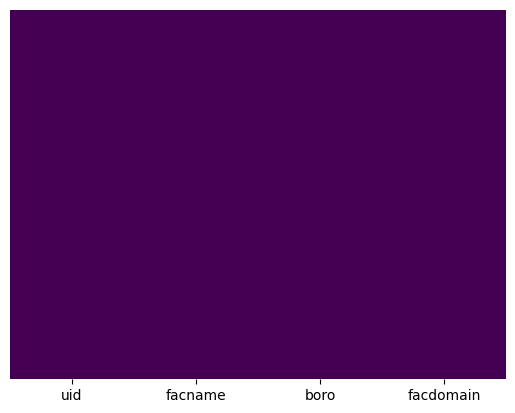

In [22]:
sns.heatmap(facilities.isnull(),yticklabels=False,cbar=False,cmap="viridis")

## RENAMING COLUMNS

In [23]:
## Renaming columns
facilities = facilities.rename(columns={
    'uid': 'Facility_ID',
    'facname': 'Facility_Name',
    'boro': 'Borough',
    'facdomain': 'Facility_Category'
})

In [24]:
comparison = facilities[
facilities['Borough'].isin(['BROOKLYN', 'BRONX'])
].copy()

In [25]:
comparison

,Facility_ID,Facility_Name,Borough,Facility_Category
1,0004a8532521d7d9879f82f67f7fb2e5,SIXTEEN SYCAMORES PLAYGROUND,BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES"
2,00056520e4c5483e13933cda8c8a736d,MARKS JCH OF BENSONHURST DAY CAMP,BROOKLYN,"EDUCATION, CHILD WELFARE, AND YOUTH"
3,0005a5ab702b05d9c4337e743af7d26d,POWELL PLAYGROUND,BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES"
5,0005d3c51109b7d8d06a3942c267b95a,G.V.C. LTD. (B2192),BRONX,CORE INFRASTRUCTURE AND TRANSPORTATION
6,00076593b6e70e9240d456da810a506b,LEESEL TRANSPORTATION CORP (B2192),BRONX,CORE INFRASTRUCTURE AND TRANSPORTATION
...,...,...,...,...
34068,K130001,SEASIDE PARK & COMMUNITY ARTS CENTER,BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES"
34069,K150001,"1809 EMMONS AVENUE, BROOKLYN, NY 11235",BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES"
34443,X010001,LA CENTRAL,BRONX,"PARKS, GARDENS, AND HISTORICAL SITES"
34444,X020001,SPOFFORD CAMPUS,BRONX,"PARKS, GARDENS, AND HISTORICAL SITES"


# Descriptive Statitistics

In [26]:
category_counts = (
    facilities.groupby(['Borough', 'Facility_Category'])['Facility_ID']
    .nunique()
    .reset_index(name='Facility_Count')
    .sort_values(
        ['Borough', 'Facility_Count'],
        ascending=[True, False]
    )
)

top_five = category_counts.groupby('Borough').head(5)
top_five

,Borough,Facility_Category,Facility_Count
2,BRONX,"EDUCATION, CHILD WELFARE, AND YOUTH",2722
3,BRONX,HEALTH AND HUMAN SERVICES,1202
1,BRONX,CORE INFRASTRUCTURE AND TRANSPORTATION,843
5,BRONX,"PARKS, GARDENS, AND HISTORICAL SITES",501
0,BRONX,ADMINISTRATION OF GOVERNMENT,157
9,BROOKLYN,"EDUCATION, CHILD WELFARE, AND YOUTH",5218
10,BROOKLYN,HEALTH AND HUMAN SERVICES,1606
8,BROOKLYN,CORE INFRASTRUCTURE AND TRANSPORTATION,1325
12,BROOKLYN,"PARKS, GARDENS, AND HISTORICAL SITES",875
11,BROOKLYN,LIBRARIES AND CULTURAL PROGRAMS,613


In [32]:
## Total facilities in each borough
total_counts = (
    comparison.groupby('Borough')['Facility_ID']
    .nunique()
    .reindex(boroughs, fill_value=0)
)
total_counts

Borough
BROOKLYN    10030
BRONX        5657
Name: Facility_ID, dtype: int64

In [ ]:
## Total category count
category_counts = (
    comparison.groupby(['Borough', 'Facility_Category'])['Facility_ID']
    .nunique()
    .reset_index(name='Facility_Count')
    .sort_values(
        ['Borough', 'Facility_Count'],
        ascending=[True, False]
    )
)

top_five = category_counts.groupby('Borough').head(5)
top_five

In [28]:
boroughs = ['BROOKLYN', 'BRONX']

total_counts = (
    comparison.groupby('Borough')['Facility_ID']
    .nunique()
    .reindex(boroughs, fill_value=0)
)

health = comparison[
    comparison['Facility_Category'] == 'HEALTH AND HUMAN SERVICES'
]

health_counts = (
    health.groupby('Borough')['Facility_ID']
    .nunique()
    .reindex(boroughs, fill_value=0)
)

summary = pd.DataFrame({
    'Total_Facilities': total_counts,
    'Health_Facilities': health_counts
})

summary['Health_Percent'] = (
    summary['Health_Facilities']
    / summary['Total_Facilities'].replace(0, float('nan'))
    * 100
).round(2)

summary

,Total_Facilities,Health_Facilities,Health_Percent
Borough,,,
BROOKLYN,10030,1606,16.01
BRONX,5657,1202,21.25


In [29]:
### Difference in health facility counts: Brooklyn minus Bronx
count_difference = (
    summary.loc['BROOKLYN', 'Health_Facilities']
    - summary.loc['BRONX', 'Health_Facilities']
)

### Difference in percentages: Brooklyn minus Bronx
percent_difference = (
    summary.loc['BROOKLYN', 'Health_Percent']
    - summary.loc['BRONX', 'Health_Percent']
)

print(f"\nCount difference (Brooklyn − Bronx): {count_difference:,}")
print(
    f"Percentage-point difference (Brooklyn − Bronx): "
    f"{percent_difference:.2f}"
)


Count difference (Brooklyn − Bronx): 404
Percentage-point difference (Brooklyn − Bronx): -5.24


# VISUALIZATION

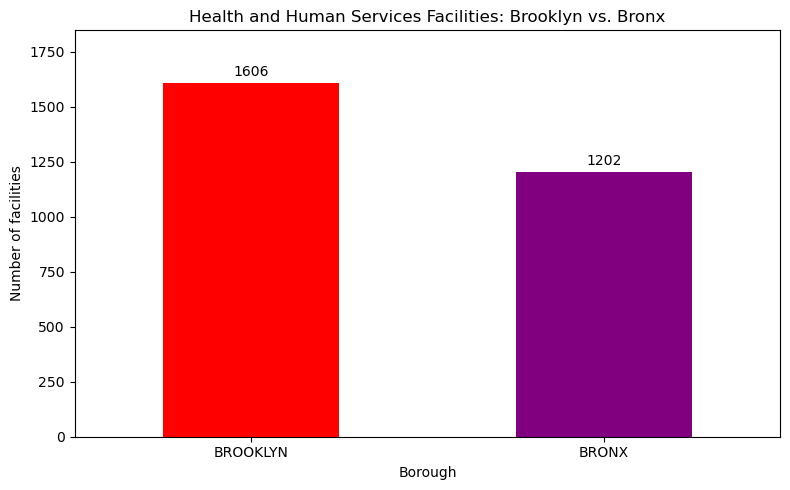

In [30]:
ax = summary['Health_Facilities'].plot(
    kind='bar',
    figsize=(8, 5),
    color=['red', 'purple'],
    rot=0
)

ax.set_title('Health and Human Services Facilities: Brooklyn vs. Bronx')
ax.set_xlabel('Borough')
ax.set_ylabel('Number of facilities')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

ax.margins(y=0.15)
plt.tight_layout()
plt.show()

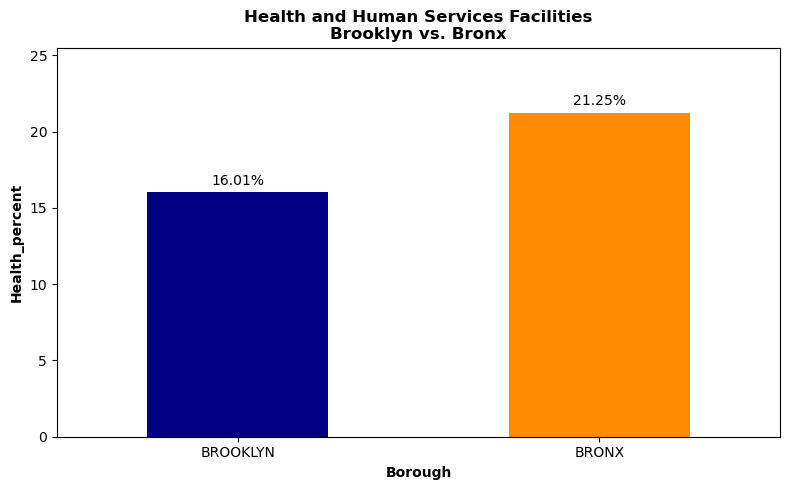

In [31]:
ax = summary['Health_Percent'].plot(
    kind='bar',
    figsize=(8, 5),
    color=['navy', 'darkorange'],
    rot=0
)

ax.set_title('Health and Human Services Facilities\nBrooklyn vs. Bronx', fontweight = "bold")
ax.set_xlabel('Borough', fontweight = "bold")
ax.set_ylabel('Health_percent', fontweight = "bold")

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

ax.set_ylim(0, max(summary['Health_Percent'].max() * 1.2, 1))

plt.tight_layout()
plt.show()

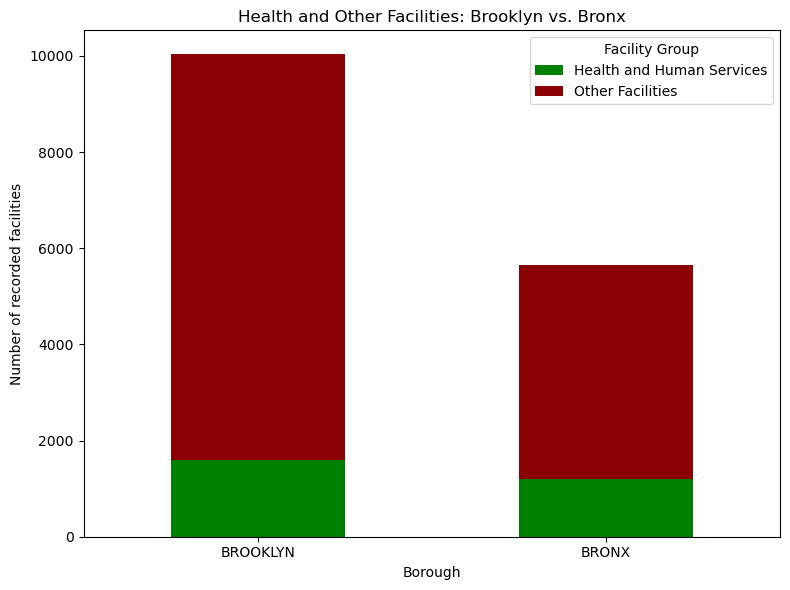

In [37]:
# Separate health facilities from all other facilities
plot_data = summary[['Health_Facilities']].copy()

plot_data['Other_Facilities'] = (
    summary['Total_Facilities'] - summary['Health_Facilities']
)

plot_data.columns = ['Health and Human Services', 'Other Facilities']

# Create the stacked bar chart
ax = plot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 6),
    color=['green', 'darkred'],
    rot=0
)

ax.set_title('Health and Other Facilities: Brooklyn vs. Bronx')
ax.set_xlabel('Borough')
ax.set_ylabel('Number of recorded facilities')
ax.legend(title='Facility Group')

plt.tight_layout()
plt.show()

Brooklyn had more health and human services facilities than the Bronx: 1,606 compared with 1,202. 
However, these facilities made up a larger share of all facilities in the Bronx—21.25%, compared with 16.01% in Brooklyn, a difference of 5.24 percentage points. This shows that Brooklyn had a higher number, while the Bronx had a higher percentage. 
These numbers do not tell us about service quality, capacity, or how easily residents can access services